# Non-linear models: polynomial, KNN, SVR, trees, random forest and boosting

Same protocol as before: shared 5 folds, RMSE on log price, scored on all houses. Following the Phase 5 decision, houses 524 and 1299 are removed from the training folds only (except where the experiment says otherwise).

Linear-type models (polynomial, KNN, SVR) use the linear preprocessor (log, scaling, one-hot). Tree models use the tree preprocessor (no log, no scaling, integer codes). CatBoost gets the categories as text.

Every model's out-of-fold predictions are saved to data/processed/oof_predictions.csv for blending and error analysis in Phase 8.

In [1]:
# Make src/ importable from notebooks/ and reload edited modules automatically
%load_ext autoreload
%autoreload 2
import sys, pathlib, warnings
from math import comb
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor, Ridge
from sklearn.model_selection import validation_curve
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, plot_tree

from src.cv import (RAW_DIR, FIGURES_DIR, SEED, CV, SCORING, evaluate_oof, fold_rmse,
                    oof_predict, show_results)
from src.models import CatBoostNativeCats
from src.features import (clean, make_catboost_preprocessor, make_linear_preprocessor,
                          make_ols_subset, make_tree_preprocessor)

warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")

train = pd.read_csv(RAW_DIR / "train.csv")
X = train.drop(columns=["Id", "SalePrice"])
y = np.log1p(train["SalePrice"])

# Phase 5 decision: 524 and 1299 never go into training, but they are always scored
keep = ~train["Id"].isin([524, 1299]).to_numpy()
NO_OUT = "no 524/1299"

# Feature names after the tree preprocessor (for plots and importances)
tree_prep = make_tree_preprocessor().fit(X)
tree_names = [n.split("__", 1)[1] for n in tree_prep.named_steps["columns"].get_feature_names_out()]
print("tree features:", len(tree_names))

tree features: 91


91 features for the tree models: the 91 columns from clean(), with categories turned into integer codes. No one-hot, no log, no scaling.

In [2]:
# Reference linear models, re-run so their out-of-fold predictions are saved for Phase 8
s_ridge, p_ridge = evaluate_oof(make_pipeline(make_linear_preprocessor(), Ridge(alpha=8.38)), X, y,
                                "Ridge (alpha=8.38)", "train without 524 & 1299", train_keep=keep,
                                phase=5, n_features=280, notes="best linear (outliers out of training)")
s_huber, p_huber = evaluate_oof(make_pipeline(make_linear_preprocessor(),
                                              HuberRegressor(epsilon=1.35, alpha=30, max_iter=5000)), X, y,
                                "Huber (alpha=30)", "linear_full", phase=5, n_features=280,
                                notes="outliers kept; alpha tuned on the same folds")

Ridge (alpha=8.38) [train without 524 & 1299]: RMSE 0.1277 ± 0.0256 | folds [0.1259, 0.112, 0.1775, 0.114, 0.109]
Huber (alpha=30) [linear_full]: RMSE 0.1261 ± 0.0229 | folds [0.1289, 0.1135, 0.1693, 0.1128, 0.1061]


Same numbers as in Phase 5 (Ridge 0.1277 without the two outliers in training, Huber 0.1261), now with their out-of-fold predictions saved for Phase 8. These are the scores the non-linear models have to beat.

In [3]:
# 1) Polynomial features + Ridge: curvature and interactions for a linear model
top5 = ["OverallQual", "GrLivArea", "TotalSF", "GarageCars", "YearBuilt"]

# How fast the number of features explodes: C(n + d, d) - 1 terms for n features up to degree d
for n in (5, 60):
    print(f"{n} features -> degree 2: {comb(n + 2, 2) - 1:5d} | degree 3: {comb(n + 3, 3) - 1:6d}")

# a) the 5 features alone, linear vs degree 2
def top5_only(degree):
    steps = [("select", FunctionTransformer(lambda df: clean(df)[top5])),
             ("impute", SimpleImputer(strategy="median")),
             ("log", FunctionTransformer(lambda a: np.c_[a[:, 0], np.log1p(a[:, 1:3]), a[:, 3:]])),
             ("scale", StandardScaler())]
    if degree > 1:
        from sklearn.preprocessing import PolynomialFeatures
        steps += [("poly", PolynomialFeatures(degree, include_bias=False)), ("scale2", StandardScaler())]
    return Pipeline(steps + [("ridge", Ridge(alpha=1.0))])

s_top5_lin, _ = evaluate_oof(top5_only(1), X, y, "Ridge (alpha=1)", f"top 5 linear, {NO_OUT}",
                             train_keep=keep, phase=6, n_features=5)
s_top5_poly, _ = evaluate_oof(top5_only(2), X, y, "Ridge (alpha=1)", f"top 5 degree 2, {NO_OUT}",
                              train_keep=keep, phase=6, n_features=20)

# b) all 280 features + the 15 squares and products of the top 5
s_poly, p_poly = evaluate_oof(make_pipeline(make_linear_preprocessor(poly_features=top5), Ridge(alpha=8.38)),
                              X, y, "Ridge + poly top 5 (alpha=8.38)", f"linear_full + 15 poly, {NO_OUT}",
                              train_keep=keep, phase=6, n_features=295)
d = s_ridge - s_poly
print(f"vs plain Ridge: mean diff {d.mean():+.4f}, better on {int((d > 0).sum())} of 5 folds")

5 features -> degree 2:    20 | degree 3:     55
60 features -> degree 2:  1890 | degree 3:  39710
Ridge (alpha=1) [top 5 linear, no 524/1299]: RMSE 0.1658 ± 0.0171 | folds [0.1695, 0.1466, 0.1936, 0.1705, 0.149]
Ridge (alpha=1) [top 5 degree 2, no 524/1299]: RMSE 0.1665 ± 0.0248 | folds [0.1657, 0.1435, 0.2127, 0.1641, 0.1463]
Ridge + poly top 5 (alpha=8.38) [linear_full + 15 poly, no 524/1299]: RMSE 0.1270 ± 0.0288 | folds [0.125, 0.1088, 0.1831, 0.1113, 0.107]
vs plain Ridge: mean diff +0.0006, better on 4 of 5 folds


The explosion is real: 5 features give 20 terms at degree 2, but 60 features would give 1,890 at degree 2 and almost 40,000 at degree 3. That's why polynomials are only practical on a handful of features.

On the 5 features alone, degree 2 doesn't help (0.1665 vs 0.1658). Fold 3 even gets worse (0.213 vs 0.194): squares of living area and total area blow up for the two huge houses, so polynomials extrapolate badly.

Adding the 15 squares and products of the top 5 to the full feature set gives 0.1270 vs 0.1277 for plain Ridge, better on 4 of 5 folds but by only 0.0006 on average. Fold 3 is again worse. A tiny gain, within the noise, so not worth the extra features.

In [4]:
# 2) KNN: predicts the average price of the k most similar houses (distance-based)
knn_rows = []
for k in (5, 10, 20):
    for label, prep, nfeat in [("17 features", make_pipeline(FunctionTransformer(make_ols_subset),
                                                             SimpleImputer(strategy="median"), StandardScaler()), 17),
                               ("280 features", make_linear_preprocessor(), 280)]:
        s, _ = evaluate_oof(make_pipeline(prep, KNeighborsRegressor(n_neighbors=k, weights="distance")), X, y,
                            f"KNN (k={k})", f"{label}, {NO_OUT}", train_keep=keep, phase=6, n_features=nfeat,
                            log=False)
        knn_rows.append({"k": k, "features": label, "RMSE": s.mean()})
knn_table = pd.DataFrame(knn_rows).pivot(index="k", columns="features", values="RMSE")
print(knn_table.round(4))

# Log the best KNN
best_k, best_set = knn_table.stack().idxmin()
prep = (make_pipeline(FunctionTransformer(make_ols_subset), SimpleImputer(strategy="median"), StandardScaler())
        if best_set == "17 features" else make_linear_preprocessor())
s_knn, p_knn = evaluate_oof(make_pipeline(prep, KNeighborsRegressor(n_neighbors=best_k, weights="distance")), X, y,
                            f"KNN (k={best_k})", f"{best_set}, {NO_OUT}", train_keep=keep, phase=6,
                            n_features=17 if best_set == "17 features" else 280, notes="k tuned on the same folds")

KNN (k=5) [17 features, no 524/1299]: RMSE 0.1645 ± 0.0146 | folds [0.1694, 0.1579, 0.1851, 0.1691, 0.1409]
KNN (k=5) [280 features, no 524/1299]: RMSE 0.1681 ± 0.0139 | folds [0.1751, 0.1778, 0.1711, 0.1758, 0.1407]
KNN (k=10) [17 features, no 524/1299]: RMSE 0.1613 ± 0.0130 | folds [0.1676, 0.1548, 0.1774, 0.1669, 0.1396]
KNN (k=10) [280 features, no 524/1299]: RMSE 0.1640 ± 0.0138 | folds [0.1723, 0.169, 0.1641, 0.177, 0.1377]
KNN (k=20) [17 features, no 524/1299]: RMSE 0.1634 ± 0.0127 | folds [0.1731, 0.1541, 0.1741, 0.1726, 0.1429]
KNN (k=20) [280 features, no 524/1299]: RMSE 0.1675 ± 0.0142 | folds [0.1788, 0.1661, 0.1687, 0.1823, 0.1419]
features  17 features  280 features
k                                  
5              0.1645        0.1681
10             0.1613        0.1640
20             0.1634        0.1675
KNN (k=10) [17 features, no 524/1299]: RMSE 0.1613 ± 0.0130 | folds [0.1676, 0.1548, 0.1774, 0.1669, 0.1396]


KNN is far behind (0.161 at best, with k = 10 on the 17 features). 280 features are a bit worse than 17 (0.164), which is the curse of dimensionality: with many features, especially hundreds of one-hot columns, "the most similar houses" stops meaning much. The effect is small here because the 17 features already carry most of the signal.

KNN's only good fold is fold 3. It predicts the average of real neighbors, so it can never produce an extreme price for the two huge houses.

In [5]:
# 3) SVR with an RBF kernel: epsilon-insensitive loss + kernel trick (needs scaling)
svr_rows = []
for C_ in (3, 10, 30):
    for gamma in (0.0003, 0.001, "scale"):
        model = make_pipeline(make_linear_preprocessor(), SVR(kernel="rbf", C=C_, gamma=gamma, epsilon=0.01))
        s = fold_rmse(y, oof_predict(model, X, y, train_keep=keep))
        svr_rows.append({"C": C_, "gamma": str(gamma), "RMSE": s.mean()})
svr_table = pd.DataFrame(svr_rows)
print(svr_table.pivot(index="C", columns="gamma", values="RMSE").round(4))

best = svr_table.loc[svr_table["RMSE"].idxmin()]
gamma = best["gamma"] if best["gamma"] == "scale" else float(best["gamma"])
s_svr, p_svr = evaluate_oof(make_pipeline(make_linear_preprocessor(),
                                          SVR(kernel="rbf", C=best["C"], gamma=gamma, epsilon=0.01)), X, y,
                            f"SVR (C={best['C']:g}, gamma={best['gamma']})", f"linear_full, {NO_OUT}",
                            train_keep=keep, phase=6, n_features=280, notes="C and gamma tuned on the same folds")

gamma  0.0003   0.001   scale
C                            
3      0.1265  0.1252  0.1393
10     0.1265  0.1270  0.1401
30     0.1263  0.1313  0.1401
SVR (C=3, gamma=0.001) [linear_full, no 524/1299]: RMSE 0.1252 ± 0.0238 | folds [0.1302, 0.1127, 0.1694, 0.1113, 0.1025]


SVR does well: 0.1252 with C = 3 and gamma = 0.001, slightly better than Ridge (better on 3 of 5 folds). C and gamma matter less than gamma's scale: gamma = "scale" (about 1/280 here) is too large, so each house only influences very close neighbors and the score drops to 0.14. With a small gamma the RBF kernel behaves almost like a smooth linear model, which is why SVR ends up close to Ridge.

C and gamma were picked on these same folds, so the score is a little optimistic.

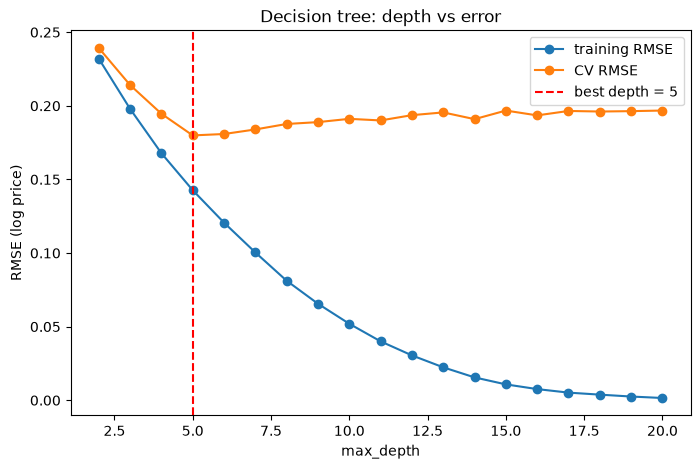

training RMSE by depth: {2: 0.232, 5: 0.143, 8: 0.081, 11: 0.04, 14: 0.016, 17: 0.005, 20: 0.002}
CV RMSE by depth:       {2: 0.239, 5: 0.18, 8: 0.188, 11: 0.19, 14: 0.191, 17: 0.197, 20: 0.197}
Decision tree (depth=5) [tree_features, no 524/1299]: RMSE 0.1893 ± 0.0181 | folds [0.2023, 0.1719, 0.2027, 0.2063, 0.1631]


In [6]:
# 4) A single decision tree: training vs CV error as the tree gets deeper
depths = np.arange(2, 21)
tree_pipe = Pipeline([("prep", make_tree_preprocessor()), ("tree", DecisionTreeRegressor(random_state=SEED))])
tr_s, cv_s = validation_curve(tree_pipe, X[keep], y[keep], param_name="tree__max_depth", param_range=depths,
                              cv=CV, scoring=SCORING, n_jobs=-1)
tr_rmse, cv_rmse = -tr_s.mean(axis=1), -cv_s.mean(axis=1)
best_depth = int(depths[cv_rmse.argmin()])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(depths, tr_rmse, marker="o", label="training RMSE")
ax.plot(depths, cv_rmse, marker="o", label="CV RMSE")
ax.axvline(best_depth, color="red", ls="--", label=f"best depth = {best_depth}")
ax.set(xlabel="max_depth", ylabel="RMSE (log price)", title="Decision tree: depth vs error")
ax.legend()
fig.savefig(FIGURES_DIR / "06_tree_depth.png", dpi=150, bbox_inches="tight")
plt.show()
print("training RMSE by depth:", dict(zip(depths[::3].tolist(), tr_rmse[::3].round(3).tolist())))
print("CV RMSE by depth:      ", dict(zip(depths[::3].tolist(), cv_rmse[::3].round(3).tolist())))

s_tree, p_tree = evaluate_oof(Pipeline([("prep", make_tree_preprocessor()),
                                        ("tree", DecisionTreeRegressor(max_depth=best_depth, random_state=SEED))]),
                              X, y, f"Decision tree (depth={best_depth})", f"tree_features, {NO_OUT}",
                              train_keep=keep, phase=6, n_features=len(tree_names), notes="depth tuned on the same folds")

The textbook overfitting picture. As the tree gets deeper, the training error goes almost to zero (0.002 at depth 20): each leaf ends up holding one or two houses. The CV error is lowest at depth 5 (0.180) and then rises: the deeper splits memorize noise.

Even the best single tree is bad: 0.189 when scored on all houses, barely better than the 2-feature linear baseline (0.1995). A single tree predicts one value per leaf, so it has only a few dozen possible prices.

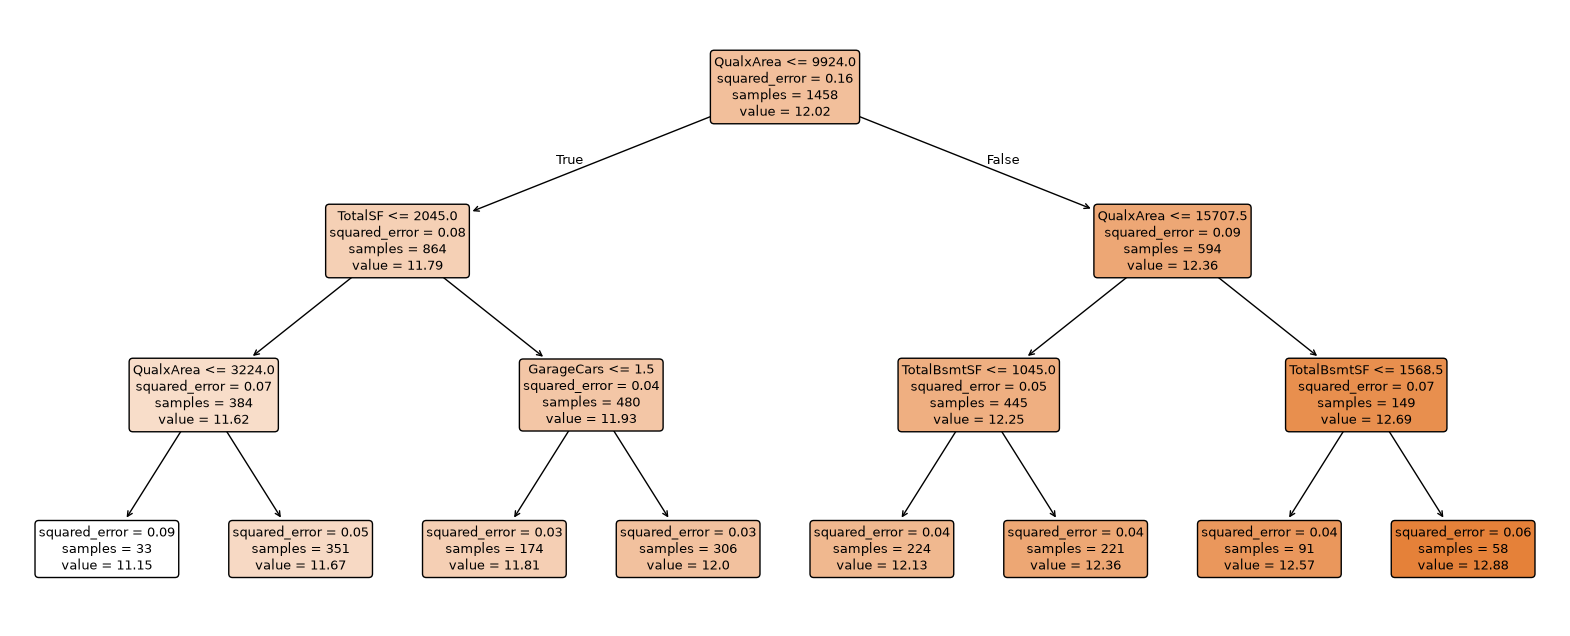

In [7]:
# A depth-3 tree, fitted on all training houses, to read its splits
small_tree = DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(tree_prep.transform(X[keep]), y[keep])
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(small_tree, feature_names=tree_names, filled=True, rounded=True, precision=2, fontsize=9, ax=ax)
fig.savefig(FIGURES_DIR / "06_tree_depth3.png", dpi=150, bbox_inches="tight")
plt.show()

The first split is on QualxArea, the quality × living area feature from Phase 2: the tree finds it the single best way to separate cheap from expensive houses. Then TotalSF, GarageCars and TotalBsmtSF.

Reading it: houses with QualxArea above 15,708 and a basement over 1,568 sq ft average 12.88 in log price (about \$390k, 58 houses). The cheapest leaf, low QualxArea and small total area, averages 11.15 (about \$70k, 33 houses). Easy to explain, but way too coarse to predict well.

OOB RMSE by number of trees: {25: 0.1403, 50: 0.1332, 100: 0.1294, 200: 0.128, 300: 0.128, 500: 0.1275}


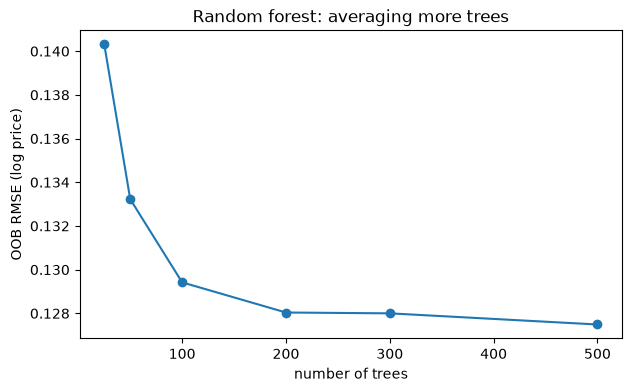

 max_features   RMSE
         0.20 0.1351
         0.33 0.1353
         0.50 0.1358
         1.00 0.1374
Random forest (500 trees, max_features=0.2) [tree_features, no 524/1299]: RMSE 0.1348 ± 0.0184 | folds [0.1443, 0.1172, 0.1621, 0.1387, 0.1117]


In [8]:
# 5) Random forest: many deep trees on bootstrap samples, averaged
# a) Out-of-bag error as trees are added: each tree is scored on the ~37% of houses it never saw
Xt_keep = tree_prep.transform(X[keep])
rf = RandomForestRegressor(max_features=0.33, oob_score=True, warm_start=True, n_jobs=-1, random_state=SEED)
n_trees, oob_rmse = [25, 50, 100, 200, 300, 500], []
for n in n_trees:
    rf.set_params(n_estimators=n).fit(Xt_keep, y[keep])
    oob_rmse.append(np.sqrt(np.mean((y[keep] - rf.oob_prediction_) ** 2)))
print("OOB RMSE by number of trees:", dict(zip(n_trees, np.round(oob_rmse, 4).tolist())))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_trees, oob_rmse, marker="o")
ax.set(xlabel="number of trees", ylabel="OOB RMSE (log price)", title="Random forest: averaging more trees")
fig.savefig(FIGURES_DIR / "06_rf_oob.png", dpi=150, bbox_inches="tight")
plt.show()

# b) max_features: how many features each split may look at (more randomness = less correlated trees)
rf_rows = []
for mf in (0.2, 0.33, 0.5, 1.0):
    model = Pipeline([("prep", make_tree_preprocessor()),
                      ("rf", RandomForestRegressor(n_estimators=300, max_features=mf, n_jobs=-1, random_state=SEED))])
    rf_rows.append({"max_features": mf, "RMSE": fold_rmse(y, oof_predict(model, X, y, train_keep=keep)).mean()})
rf_table = pd.DataFrame(rf_rows)
print(rf_table.round(4).to_string(index=False))

best_mf = float(rf_table.loc[rf_table["RMSE"].idxmin(), "max_features"])
s_rf, p_rf = evaluate_oof(Pipeline([("prep", make_tree_preprocessor()),
                                    ("rf", RandomForestRegressor(n_estimators=500, max_features=best_mf,
                                                                 n_jobs=-1, random_state=SEED))]),
                          X, y, f"Random forest (500 trees, max_features={best_mf:g})", f"tree_features, {NO_OUT}",
                          train_keep=keep, phase=6, n_features=len(tree_names), notes="max_features tuned on the same folds")

Out-of-bag error drops quickly as trees are added (0.140 with 25 trees, 0.128 with 200) and then flattens (0.1275 with 500). More trees never make it worse; they just stop helping. That's bagging: averaging reduces variance, and the error levels off at the bias of the trees.

max_features barely matters (0.135 to 0.137); 0.2 is best, so more randomness per split is fine here.

The CV score (0.1348) is worse than Ridge, better on only 1 of 5 folds. (The OOB number is lower because it excludes 524 and 1299, which aren't in the training data; the CV score includes them.) Random forest averages deep trees but can't model the smooth, almost linear-in-log relationships as well as a linear model, and it can't extrapolate.

In [9]:
# 6) Gradient boosting: many small trees, each one fitting what the previous ones got wrong.
# Reasonable untuned settings; tuning comes in Phase 7.
boosters = {
    "HistGradientBoosting": HistGradientBoostingRegressor(
        learning_rate=0.05, max_iter=800, max_leaf_nodes=15, min_samples_leaf=10,
        l2_regularization=1.0, random_state=SEED),
    "LightGBM": LGBMRegressor(
        n_estimators=2000, learning_rate=0.01, num_leaves=15, min_child_samples=10,
        subsample=0.7, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
        random_state=SEED, verbose=-1),
    "XGBoost": XGBRegressor(
        n_estimators=2000, learning_rate=0.01, max_depth=4, min_child_weight=1,
        subsample=0.7, colsample_bytree=0.5, reg_lambda=1.0, tree_method="hist", random_state=SEED),
}
boost_scores, boost_pred = {}, {}
for name, reg in boosters.items():
    boost_scores[name], boost_pred[name] = evaluate_oof(
        Pipeline([("prep", make_tree_preprocessor()), ("model", reg)]), X, y, name, f"tree_features, {NO_OUT}",
        train_keep=keep, phase=6, n_features=len(tree_names), params=reg.get_params(), notes="untuned")

# CatBoost with native categoricals: the categories stay as text, no one-hot and no integer codes
cat_cols = clean(X).select_dtypes(exclude="number").columns.tolist()
cat_model = Pipeline([("prep", make_catboost_preprocessor()),
                      ("model", CatBoostNativeCats(iterations=1500, learning_rate=0.03, depth=6, l2_leaf_reg=3,
                                                   random_seed=SEED))])
boost_scores["CatBoost"], boost_pred["CatBoost"] = evaluate_oof(
    cat_model, X, y, "CatBoost", f"native categoricals, {NO_OUT}", train_keep=keep, phase=6,
    n_features=len(tree_names), notes=f"untuned; {len(cat_cols)} categorical columns as text")

HistGradientBoosting [tree_features, no 524/1299]: RMSE 0.1282 ± 0.0218 | folds [0.1364, 0.1103, 0.1663, 0.1224, 0.1055]
LightGBM [tree_features, no 524/1299]: RMSE 0.1252 ± 0.0207 | folds [0.1308, 0.1071, 0.1621, 0.1203, 0.1056]
XGBoost [tree_features, no 524/1299]: RMSE 0.1220 ± 0.0194 | folds [0.1275, 0.1084, 0.1569, 0.1156, 0.1018]
CatBoost [native categoricals, no 524/1299]: RMSE 0.1219 ± 0.0146 | folds [0.1324, 0.1086, 0.1437, 0.1199, 0.1048]


The boosters are the best models so far, all untuned:
- CatBoost 0.1219 ± 0.015, with the lowest spread across folds
- XGBoost 0.1220
- LightGBM 0.1252
- HistGradientBoosting 0.1282

But the gain over Ridge (0.1277) is small, and it's not consistent fold by fold. CatBoost is better on 3 of 5 folds, and most of its lead comes from fold 3 (0.144 vs 0.178): it predicts much more reasonable prices for the two huge outlier houses. On folds 1 and 4 Ridge is better.

So boosting wins here by a little, not a lot. With only about 1,450 houses and relationships that are already close to linear in log space, a well-built linear model is hard to beat.

CatBoost uses the 31 categorical columns as text, with its own encoding, instead of one-hot or integer codes.

best iteration: 804 | validation RMSE there: 0.1302


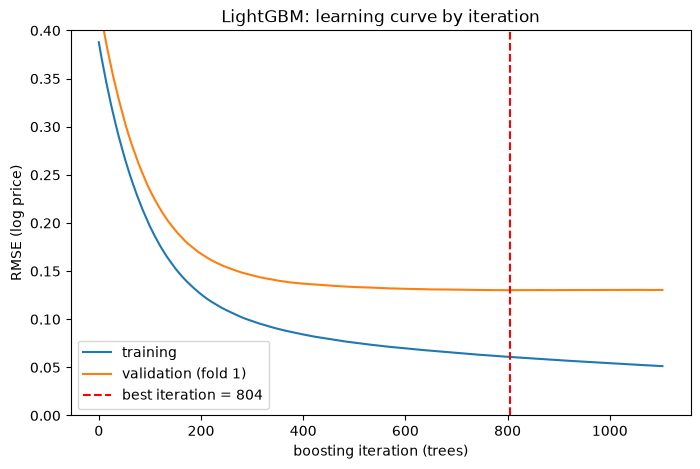

In [10]:
# 7) LightGBM with early stopping on one fold: training vs validation loss per iteration
tr_idx, va_idx = next(CV.split(X))
tr_idx = tr_idx[keep[tr_idx]]
prep = make_tree_preprocessor().fit(X.iloc[tr_idx])
Xtr, Xva = prep.transform(X.iloc[tr_idx]), prep.transform(X.iloc[va_idx])

history = {}
es_model = LGBMRegressor(n_estimators=5000, learning_rate=0.01, num_leaves=15, min_child_samples=10,
                         subsample=0.7, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
                         random_state=SEED, verbose=-1)
es_model.fit(Xtr, y.iloc[tr_idx],
             eval_X=(Xtr, Xva), eval_y=(y.iloc[tr_idx], y.iloc[va_idx]),
             eval_names=["training", "validation"], eval_metric="rmse",
             callbacks=[lgb.early_stopping(300, verbose=False), lgb.record_evaluation(history)])
best_it = es_model.best_iteration_
print(f"best iteration: {best_it} | validation RMSE there: {history['validation']['rmse'][best_it - 1]:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history["training"]["rmse"], label="training")
ax.plot(history["validation"]["rmse"], label="validation (fold 1)")
ax.axvline(best_it, color="red", ls="--", label=f"best iteration = {best_it}")
ax.set(xlabel="boosting iteration (trees)", ylabel="RMSE (log price)", ylim=(0, 0.4),
       title="LightGBM: learning curve by iteration")
ax.legend()
fig.savefig(FIGURES_DIR / "06_lgbm_early_stopping.png", dpi=150, bbox_inches="tight")
plt.show()

Both curves drop fast in the first 200 trees. After that, the training error keeps going down (0.05 at 1,100 trees) while the validation error flattens around 0.130. Early stopping picks 804 trees.

The gap between the two curves is the overfitting. With a small learning rate (0.01) it creeps in very slowly, so the validation error stays almost flat from 500 to 1,100 trees. That's the trade-off: a small learning rate needs more trees but is forgiving about exactly how many. The CV runs used 2,000 trees, a bit past the best point; tuning in Phase 7 will fix that.

In [11]:
# 8) The outlier experiment for LightGBM (same fair setup as Phase 5)
is_big4 = (train["GrLivArea"] > 4000).to_numpy()
lgbm_pipe = Pipeline([("prep", make_tree_preprocessor()), ("model", boosters["LightGBM"])])
for label, mask in [("keep all", None), ("drop 524 & 1299", keep)]:
    pred = oof_predict(lgbm_pipe, X, y, train_keep=mask)
    print(f"LightGBM {label:16s}: all houses {fold_rmse(y, pred).mean():.4f} | "
          f"without the 4 big {fold_rmse(y, pred, ~is_big4).mean():.4f} | "
          f"predicted $ for 524, 1299: {np.expm1(pred[~keep]).round(-3).tolist()}")

LightGBM keep all        : all houses 0.1266 | without the 4 big 0.1168 | predicted $ for 524, 1299: [691000.0, 636000.0]
LightGBM drop 524 & 1299 : all houses 0.1252 | without the 4 big 0.1159 | predicted $ for 524, 1299: [691000.0, 636000.0]


Removing 524 and 1299 from training helps LightGBM only a little (0.1266 to 0.1252 on all houses, 0.1168 to 0.1159 on normal ones), much less than for Ridge (0.1316 to 0.1277). A tree can only put an extreme house into a leaf; it can't tilt a line for everyone, so outliers have less pull.

LightGBM predicts about \$690k and \$640k for the two outliers (Ridge: \$700k and \$1.2M). Still very wrong, but a tree can't predict beyond the prices it has seen.

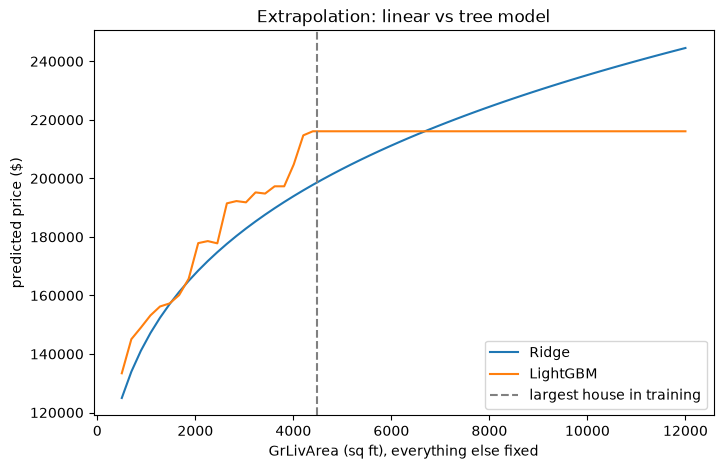

  2000 sq ft -> Ridge $168,496 | LightGBM $177,878
  4000 sq ft -> Ridge $193,959 | LightGBM $204,764
  8000 sq ft -> Ridge $223,903 | LightGBM $216,088
 12000 sq ft -> Ridge $244,542 | LightGBM $216,088


In [12]:
# 9) Extrapolation: one ordinary house, living area pushed far beyond anything in training
base = X[keep].iloc[[int(np.argmin(np.abs(y[keep] - y[keep].median())))]]   # the median-priced house
areas = np.linspace(500, 12000, 60)
grid = pd.concat([base] * len(areas), ignore_index=True)
grid["GrLivArea"] = areas

ridge_full = make_pipeline(make_linear_preprocessor(), Ridge(alpha=8.38)).fit(X[keep], y[keep])
lgbm_full = Pipeline([("prep", make_tree_preprocessor()), ("model", boosters["LightGBM"])]).fit(X[keep], y[keep])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(areas, np.expm1(ridge_full.predict(grid)), label="Ridge")
ax.plot(areas, np.expm1(lgbm_full.predict(grid)), label="LightGBM")
ax.axvline(X.loc[keep, "GrLivArea"].max(), color="grey", ls="--", label="largest house in training")
ax.set(xlabel="GrLivArea (sq ft), everything else fixed", ylabel="predicted price ($)",
       title="Extrapolation: linear vs tree model")
ax.legend()
fig.savefig(FIGURES_DIR / "06_extrapolation.png", dpi=150, bbox_inches="tight")
plt.show()
for a in (2000, 4000, 8000, 12000):
    i = int(np.argmin(np.abs(areas - a)))
    print(f"{a:6d} sq ft -> Ridge ${np.expm1(ridge_full.predict(grid.iloc[[i]]))[0]:,.0f} | "
          f"LightGBM ${np.expm1(lgbm_full.predict(grid.iloc[[i]]))[0]:,.0f}")

The difference between the two model families in one picture. Inside the training range both follow the same trend; LightGBM moves in steps because it's built from splits.

Beyond the largest house in training (dashed line), LightGBM is completely flat at \$216k: 8,000 and 12,000 sq ft get the same price. Ridge keeps going up (\$224k at 8,000, \$245k at 12,000), following its log-linear trend.

A house twice the size of anything in the data: Lasso or Ridge would extrapolate the trend (maybe too much, maybe too little), LightGBM would give it the price of the biggest house it has seen. Neither should be trusted that far out.

In [13]:
# Fold by fold against the best linear model (Ridge without 524/1299)
contenders = {"Huber": s_huber, "Ridge + poly": s_poly, f"KNN": s_knn, "SVR": s_svr, "Decision tree": s_tree,
              "Random forest": s_rf, **boost_scores}
print("Ridge folds:", s_ridge.round(4).tolist())
for name, s in contenders.items():
    d = s_ridge - s
    print(f"{name:22s} RMSE {s.mean():.4f} | diff vs Ridge {d.mean():+.4f} | better on {int((d > 0).sum())} of 5 folds")

# How similar are the errors of the linear and tree models? (low correlation = good for blending)
errors = pd.DataFrame({"Ridge": y - p_ridge, "SVR": y - p_svr, "LightGBM": y - boost_pred["LightGBM"],
                       "CatBoost": y - boost_pred["CatBoost"], "Random forest": y - p_rf})
print("\ncorrelation of out-of-fold errors:\n", errors[keep].corr().round(2))

Ridge folds: [0.1259, 0.112, 0.1775, 0.114, 0.109]
Huber                  RMSE 0.1261 | diff vs Ridge +0.0016 | better on 3 of 5 folds
Ridge + poly           RMSE 0.1270 | diff vs Ridge +0.0006 | better on 4 of 5 folds
KNN                    RMSE 0.1613 | diff vs Ridge -0.0336 | better on 1 of 5 folds
SVR                    RMSE 0.1252 | diff vs Ridge +0.0024 | better on 3 of 5 folds
Decision tree          RMSE 0.1893 | diff vs Ridge -0.0616 | better on 0 of 5 folds
Random forest          RMSE 0.1348 | diff vs Ridge -0.0071 | better on 1 of 5 folds
HistGradientBoosting   RMSE 0.1282 | diff vs Ridge -0.0005 | better on 3 of 5 folds
LightGBM               RMSE 0.1252 | diff vs Ridge +0.0025 | better on 3 of 5 folds
XGBoost                RMSE 0.1220 | diff vs Ridge +0.0056 | better on 3 of 5 folds
CatBoost               RMSE 0.1219 | diff vs Ridge +0.0058 | better on 3 of 5 folds

correlation of out-of-fold errors:
                Ridge   SVR  LightGBM  CatBoost  Random forest
Ridge     

Fold by fold, nothing beats Ridge consistently:
- XGBoost and CatBoost are the best on average (+0.006), but better on only 3 of 5 folds, with most of the gain on fold 3
- SVR, LightGBM and Huber: +0.002, 3 of 5 folds
- Random forest, the single tree and KNN are worse

The error correlations are more interesting for Phase 8. Ridge and SVR make very similar errors (0.92), and so do LightGBM and CatBoost (0.94). Between the families it's lower: Ridge vs LightGBM 0.85, Ridge vs CatBoost 0.87, Ridge vs Random forest 0.76. Linear and tree models get different houses wrong, so blending a linear model with a booster should help more than blending two boosters.

In [14]:
# The results table so far
print(show_results().to_string())

    phase                                        model                         feature_set  n_features  cv_rmse_mean  cv_rmse_std                                              notes
0       6                                     CatBoost    native categoricals, no 524/1299          91       0.12191      0.01456            untuned; 31 categorical columns as text
1       6                                      XGBoost          tree_features, no 524/1299          91       0.12205      0.01938                                            untuned
2       6                                     LightGBM          tree_features, no 524/1299          91       0.12520      0.02065                                            untuned
3       6                       SVR (C=3, gamma=0.001)            linear_full, no 524/1299         280       0.12523      0.02385                C and gamma tuned on the same folds
4       5                             Huber (alpha=30)                         linear_full     

Top of the table: CatBoost (0.1219), XGBoost (0.1220), then LightGBM and SVR (0.1252), Huber (0.1261) and Ridge with poly terms (0.1270). The top 6 are within 0.005 of each other, about the size of the fold-to-fold noise.

## Where I am after Phase 6

Boosting is the best model family here, but only by a little: untuned CatBoost and XGBoost get about 0.122 vs 0.128 for Ridge, and they're better on only 3 of 5 folds. Much of their lead comes from the fold with the two huge outlier houses, where trees can't produce extreme predictions.

What each model family showed:
- Polynomial terms: almost no gain, and they extrapolate badly for the huge houses.
- KNN: weak, and worse with more features (curse of dimensionality).
- SVR: as good as the best linear models once gamma is small.
- Single tree: memorizes with depth; even the best one is barely better than 2-feature linear regression.
- Random forest: more trees never hurt, but it's worse than Ridge here.
- Boosting: the best, with a small learning rate making it forgiving about the number of trees.

Trees are less sensitive to the outliers than linear models, and they can't extrapolate beyond the largest house they've seen.

Linear and tree models make fairly different errors (correlation about 0.85), which is promising for blending in Phase 8.

Next, Phase 7: tune the best booster with Optuna, learning curves for bias and variance, and SHAP to explain the model.